In this project i have five script file and one notebook files to organize the project in a modular manner. and those files are:
 - <span style="color:magenta">data_up.py</span> - it is for loading the data using ImageFolder and Dataloader module of pyTorch.
 - <span style="color:magenta">model_buildr.py</span> - is used for define the architecture of the model(TinyVGG) model architecture used in this case.
 - <span style="color:magenta">engine.py </span>- is all about defining the training and testing loops of the model.
 - <span style="color:magenta">utils.py</span> - is a script for save the model and laod the model to and from local disk.
 - <span style="color:magenta">main.py </span>- it is for run all scripts and the main app of the project.
 - <span style="color:magenta">index.ipynb</span> - it is notebook file used to experment and visual purpose of the project.
# 1. Import Libraries

In [1]:
import os
from pathlib import Path

import torch
import importlib

During working with machine learning and neural network, the device configration are important to be protect the divice mismached errors. this types of jobs are needs high conputational power then it needs good computetional power device, for huge project GPU/Cuda are the best option, but during this type properly handle the device mismahced during training, both data and model should be on the same device in order to run the model without error. 

In order to handle this type of runtime error device agnostic code is necessary at the to of your project.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# 2. Preprocessing 
<span style="color:magenta">data_setup.py </span>- script are responsible for downloading and organizing the dataset for the next processing of the project. manly its function is downloading and arrange the dataset using <span style="color:orange">ImageFolder</span> and <span style="color:orange">DataLoader</span> moduls of the pyTorch module.
- **ImageFolder** - is used for assign the label of integer number start from zero for each class(folders of classification) and then indexed all of the images and return indexed image path and lavel for the specific data(image)
- **DataLoader** - are works with ImageFolder, the output from imagefolder are feed to DataLoader which is load the data to the model by batching and shufling(for train dataset anly).

In [3]:
from going_modular.data_setup import check_data

# This method checking if there is the dataset on the disk(if not download the dataset)
data_path = Path("m_data")
image_path = data_path / "pizza_steak_sushi"
check_data(data_path = data_path, 
           image_path = image_path)

# image paths for train and test datas.
train_dir = image_path / "train"
test_dir = image_path / "test"
Batch_size = 32
num_workers = os.cpu_count()

m_data directory already exists, skipping download.


<span style="color:orange">Other steps done with engine script
</span>

### 3. Define TinyVGG model Architecture
- This specific file of the project is focusing on defining the model architecture. my model is based on TinyVGG arcitecture and it have two stacked collection of convolutional layers and the third layer for linear(fully connected) layer. each stack have a series of its owen 2D convolutional layers wrapped with activation function(in this case ReLU layer), 
### 4. Define Training Loop
### 5. Save Model
### 6. Load Model
# 7. Train Model

In [8]:
import main as main
main = importlib.reload(main)

#  path(__file__) for script and path().cwd() for notebook
 # Setup directories
train_dir = "m_data/pizza_steak_sushi/train"
test_dir = "m_data/pizza_steak_sushi/test"
model_dir = Path().cwd()/"model"       # This points to the current working directory and then to the model directory

model, test_dataloader, class_names, train_result = main.main(train_dir=train_dir, 
                                                test_dir=test_dir, 
                                                save_dir=model_dir)

  0%|          | 0/8 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1714   |   train_acc: 0.2656   |   test_loss: 1.1045   |   test_acc: 0.1979
Epoch: 2 | train_loss: 1.0687   |   train_acc: 0.4141   |   test_loss: 1.1344   |   test_acc: 0.1979
Epoch: 3 | train_loss: 0.9969   |   train_acc: 0.4688   |   test_loss: 1.0127   |   test_acc: 0.4830
Epoch: 4 | train_loss: 0.9375   |   train_acc: 0.5781   |   test_loss: 0.9879   |   test_acc: 0.4725
Epoch: 5 | train_loss: 0.9712   |   train_acc: 0.4766   |   test_loss: 0.9793   |   test_acc: 0.4233
Epoch: 6 | train_loss: 0.8689   |   train_acc: 0.6289   |   test_loss: 0.9875   |   test_acc: 0.4337
Epoch: 7 | train_loss: 0.7872   |   train_acc: 0.6484   |   test_loss: 1.0351   |   test_acc: 0.4034
Epoch: 8 | train_loss: 0.9306   |   train_acc: 0.5391   |   test_loss: 0.9837   |   test_acc: 0.4451
Saving the model to: /home/nigatie/Documents/ML_DL/Deep_Learning/Modularity/model/05_going_modular_script_mode_tinyvgg_model.pth
Model saved successfully!


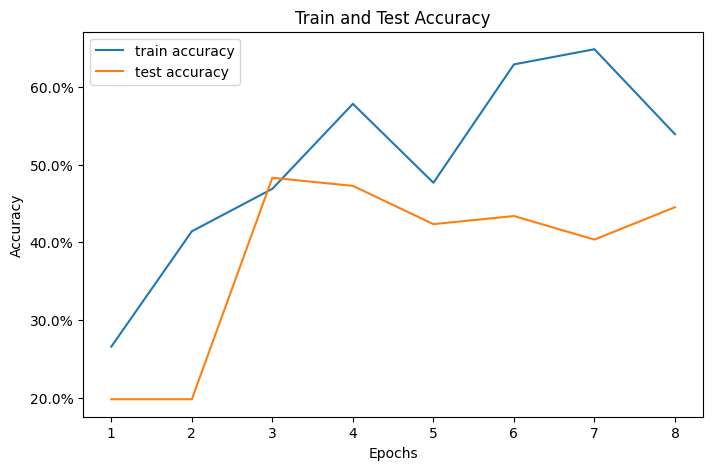

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
plt.figure(figsize=(8, 5))
plt.plot(train_result["train_acc"], label="train accuracy")
plt.plot(train_result["test_accu"], label="test accuracy")
plt.title("Train and Test Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0)) 
plt.xticks(ticks=range(len(train_result["train_acc"])), labels=range(1, len(train_result["train_acc"])+1))   # type: ignore
plt.legend()
plt.show()

['pizza', 'steak', 'sushi']
              precision    recall  f1-score   support

           0       0.50      0.48      0.49        25
           1       0.50      0.84      0.63        19
           2       0.47      0.29      0.36        31

    accuracy                           0.49        75
   macro avg       0.49      0.54      0.49        75
weighted avg       0.49      0.49      0.47        75



,precision,Recall,f1_score
correctness,49.12%,53.75%,49.24%


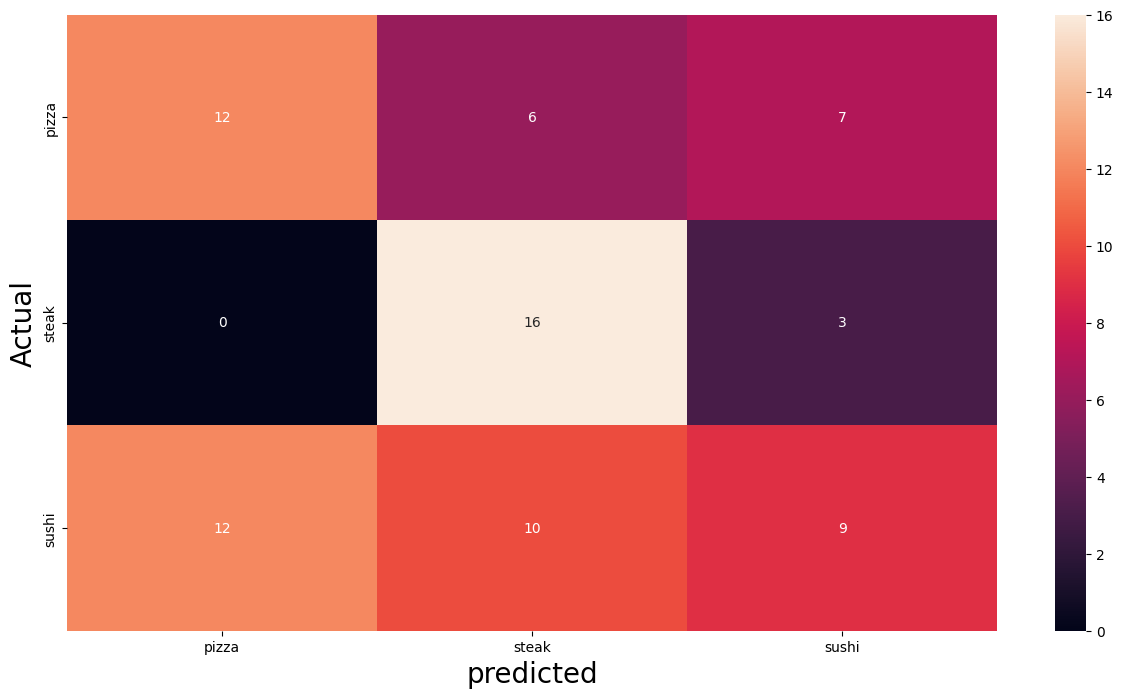

In [30]:
import going_modular.evaluation as eval
eval = importlib.reload(eval)
import pandas as pd

print(class_names)
resulat, conf_matrics = eval.evaluation(model=model, 
                     test_data= test_dataloader, 
                     device = device)

evaluation_result = pd.DataFrame(resulat, index=["correctness"])
display(evaluation_result)
eval.plot_conf_metrics(conf_matrics, 
                  class_name = class_names) # type: ignore